[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matveyyaros/Project-activities-case-9/blob/ruslan/notebooks/02_modeling.ipynb)

# 🤖 **Модель прогноза урожая черники**

**Задача:** предсказать урожай (`yield`) по условиям сезона — размеру клона, плотности опылителей и погоде.
**Тип задачи:** регрессия (предсказываем число).
**Основа:** выводы тетрадки `EDA_wildblueberry.ipynb` — очистка данных и выбор признаков взяты оттуда.

План:
1. Подготовка данных (как в EDA).
2. Разбиение на обучающую и тестовую выборки.
3. Сравнение моделей кросс-валидацией.
4. Подбор параметров лучшей модели.
5. Финальная проверка на тесте.
6. Интерпретация: какие факторы важны и что даст хозяйству больше пчёл.
7. Сохранение модели.

## 📚 **Импорты и настройки**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# XGBoost есть в Google Colab. На Mac ему нужна системная библиотека libomp;
# если её нет, тетрадка работает на градиентном бустинге из scikit-learn.
try:
    from xgboost import XGBRegressor
    XGBRegressor().fit(np.zeros((2, 1)), [0, 1])  # проверка, что библиотека реально загружается
    HAS_XGB = True
except Exception as e:
    HAS_XGB = False
    print(f"⚠️ XGBoost недоступен ({type(e).__name__}), используем HistGradientBoostingRegressor")

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
print(f"XGBoost доступен: {HAS_XGB}")

⚠️ XGBoost недоступен (XGBoostError), используем HistGradientBoostingRegressor
XGBoost доступен: False


---
# **1. Подготовка данных**

Повторяем решения из EDA:
- убираем 18 строк особого блока (Row# 759–776) — это отдельная серия экспериментов;
- убираем `Row#`;
- из шести температурных столбцов оставляем `AverageOfUpperTRange`, из двух столбцов про дождь — `RainingDays`;
- `fruitset`, `fruitmass`, `seeds` — утечка цели, в основную модель не берём.

In [2]:
# Корень проекта: папка с pyproject.toml. В Colab её нет — тогда работаем в текущей папке.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    ROOT = Path.cwd()

DATA_PATH = ROOT / "data" / "raw" / "WildBlueberryPollinationSimulationData.csv"
DATA_URL = ("https://raw.githubusercontent.com/matveyyaros/Project-activities-case-9/"
            "506b161/data/raw/WildBlueberryPollinationSimulationData.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print(f"📂 Данные загружены из файла: {DATA_PATH}")
else:
    df = pd.read_csv(DATA_URL)
    print("🌐 Локального файла нет, данные загружены с GitHub")
print(f"Строк: {df.shape[0]}, столбцов: {df.shape[1]}")

📂 Данные загружены из файла: /Users/ruslan/Project-activities-case-9/data/raw/WildBlueberryPollinationSimulationData.csv
Строк: 777, столбцов: 18


In [3]:
# Основная сетка эксперимента (см. EDA, раздел 3.3)
df_clean = df[df["clonesize"].isin([12.5, 25, 37.5])].drop(columns="Row#").reset_index(drop=True)

FACTORS = ["clonesize", "honeybee", "bumbles", "andrena", "osmia", "AverageOfUpperTRange", "RainingDays"]
OUTCOMES = ["fruitset", "fruitmass", "seeds"]   # утечка цели
TARGET = "yield"

X = df_clean[FACTORS]
y = df_clean[TARGET]
print(f"📊 Строк для моделирования: {len(df_clean)}, признаков: {len(FACTORS)}")
X.head()

📊 Строк для моделирования: 759, признаков: 7


,clonesize,honeybee,bumbles,andrena,osmia,AverageOfUpperTRange,RainingDays
0,37.5,0.75,0.25,0.25,0.25,71.9,16.0
1,37.5,0.75,0.25,0.25,0.25,71.9,1.0
2,37.5,0.75,0.25,0.25,0.25,79.0,16.0
3,37.5,0.75,0.25,0.25,0.25,79.0,1.0
4,37.5,0.75,0.25,0.25,0.25,71.9,24.0


---
# **2. Обучающая и тестовая выборки**

Откладываем **20 % данных в тест** и не трогаем их до самого конца. Модели сравниваем и настраиваем только на оставшихся 80 %.
Так оценка на тесте честно показывает, как модель поведёт себя на новых данных.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"🏋️ Обучение: {len(X_train)} строк")
print(f"🧪 Тест:     {len(X_test)} строк")

🏋️ Обучение: 607 строк
🧪 Тест:     152 строк


---
# **3. Сравнение моделей**

**Кросс-валидация на 5 частях:** обучающая выборка делится на 5 частей, модель 5 раз обучается на четырёх и проверяется на пятой. Результат усредняется — так оценка устойчивее, чем по одному разбиению.

**Метрики:**
- **MAE** — средняя ошибка в единицах урожая (меньше — лучше);
- **RMSE** — то же, но сильнее штрафует крупные промахи;
- **R²** — какую долю разброса урожая объясняет модель: 1 — идеально, 0 — не лучше среднего.

**Модели — от простой к сложной:**
- **среднее** — всегда предсказывает средний урожай; точка отсчёта, хуже неё быть нельзя;
- **линейная регрессия** — урожай как взвешенная сумма факторов;
- **Random Forest** — среднее по многим деревьям решений;
- **градиентный бустинг** (XGBoost или его аналог из scikit-learn) — деревья строятся по очереди, каждое исправляет ошибки предыдущих.

In [5]:
def make_boosting(**params):
    if HAS_XGB:
        return XGBRegressor(random_state=RANDOM_STATE, n_estimators=400, learning_rate=0.05, max_depth=4, **params)
    return HistGradientBoostingRegressor(random_state=RANDOM_STATE, **params)

BOOST_NAME = "XGBoost" if HAS_XGB else "HistGradientBoosting"

models = {
    "Среднее (baseline)": DummyRegressor(),
    "Линейная регрессия": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    BOOST_NAME: make_boosting(),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Модель": name,
                 "MAE": -res["test_MAE"].mean(),
                 "RMSE": -res["test_RMSE"].mean(),
                 "R²": res["test_R2"].mean()})

cv_results = pd.DataFrame(rows).set_index("Модель").sort_values("MAE")
cv_results.round(3)

,MAE,RMSE,R²
Модель,,,
HistGradientBoosting,165.711,213.774,0.974
Random Forest,199.116,256.194,0.963
Линейная регрессия,512.653,617.727,0.784
Среднее (baseline),1095.757,1340.993,-0.012


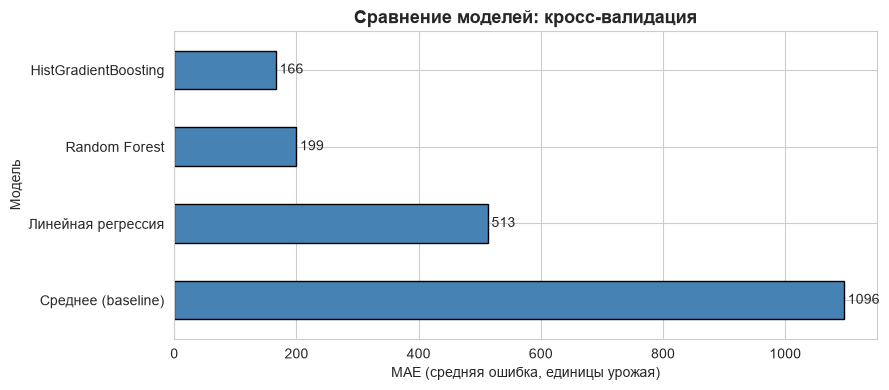

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
cv_results["MAE"].sort_values(ascending=False).plot(kind="barh", ax=ax, color="steelblue", edgecolor="black")
ax.set_xlabel("MAE (средняя ошибка, единицы урожая)")
ax.set_title("Сравнение моделей: кросс-валидация", fontsize=13, fontweight="bold")
for i, v in enumerate(cv_results["MAE"].sort_values(ascending=False)):
    ax.text(v, i, f" {v:.0f}", va="center")
plt.tight_layout()
plt.show()

### 💡 Что видно
- Любая модель намного лучше среднего — факторы действительно определяют урожай.
- Деревья (Random Forest, бустинг) заметно точнее линейной регрессии. Это согласуется с EDA: связи **нелинейные** — у температуры есть оптимум посередине, у андрен и осмий прирост урожая с ростом плотности замедляется.

### Для сравнения: модель с утечкой цели
Что будет, если добавить `fruitset`, `fruitmass` и `seeds`? Точность вырастет, но такая модель бесполезна для планирования: эти величины известны только вместе с урожаем.

In [7]:
X_leak_train = df_clean.loc[X_train.index, FACTORS + OUTCOMES]
res = cross_validate(LinearRegression(), X_leak_train, y_train, cv=cv, scoring=scoring)
print(f"Линейная регрессия С утечкой:  MAE = {-res['test_MAE'].mean():.0f}, R² = {res['test_R2'].mean():.3f}")
print(f"Линейная регрессия БЕЗ утечки: MAE = {cv_results.loc['Линейная регрессия', 'MAE']:.0f}, "
      f"R² = {cv_results.loc['Линейная регрессия', 'R²']:.3f}")

Линейная регрессия С утечкой:  MAE = 94, R² = 0.991
Линейная регрессия БЕЗ утечки: MAE = 513, R² = 0.784


Почти идеальная точность с утечкой — это «подсмотренный ответ». Дальше работаем **только с факторами**.

---
# **4. Подбор параметров бустинга**

У бустинга есть **гиперпараметры** — настройки, которые задаются до обучения: число деревьев, их глубина, скорость обучения и др.
`RandomizedSearchCV` перебирает 30 случайных комбинаций и для каждой считает кросс-валидацию — выбираем лучшую.

In [8]:
if HAS_XGB:
    param_dist = {
        "n_estimators": [200, 400, 600, 800],
        "max_depth": [2, 3, 4, 5, 6],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "subsample": [0.7, 0.85, 1.0],
        "colsample_bytree": [0.7, 0.85, 1.0],
        "min_child_weight": [1, 3, 5],
    }
    base = XGBRegressor(random_state=RANDOM_STATE)
else:
    param_dist = {
        "max_iter": [200, 400, 600, 800],
        "max_depth": [2, 3, 4, 5, None],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "min_samples_leaf": [5, 10, 20],
        "l2_regularization": [0.0, 0.1, 1.0],
    }
    base = HistGradientBoostingRegressor(random_state=RANDOM_STATE)

search = RandomizedSearchCV(base, param_dist, n_iter=30, cv=cv, scoring="neg_mean_absolute_error",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)

best_model = search.best_estimator_
print(f"🏆 Лучшие параметры {BOOST_NAME}:")
for k, v in search.best_params_.items():
    print(f"   {k} = {v}")
print(f"\nMAE на кросс-валидации: до подбора {cv_results.loc[BOOST_NAME, 'MAE']:.0f}, после {-search.best_score_:.0f}")

🏆 Лучшие параметры HistGradientBoosting:
   min_samples_leaf = 10
   max_iter = 400
   max_depth = 4
   learning_rate = 0.1
   l2_regularization = 0.1

MAE на кросс-валидации: до подбора 166, после 156


---
# **5. Финальная проверка на тесте**

Теперь — впервые — смотрим на отложенные 20 %. Это честная оценка качества на данных, которые модель не видела.

In [9]:
y_pred = best_model.predict(X_test)

test_metrics = pd.Series({
    "MAE": mean_absolute_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "MAPE, %": mean_absolute_percentage_error(y_test, y_pred) * 100,
    "R²": r2_score(y_test, y_pred),
})
print(f"📏 Качество {BOOST_NAME} на тесте:")
print(test_metrics.round(3).to_string())
print(f"\nДля масштаба: средний урожай в тесте {y_test.mean():.0f}")

📏 Качество HistGradientBoosting на тесте:
MAE        148.931
RMSE       193.585
MAPE, %      2.607
R²           0.979

Для масштаба: средний урожай в тесте 6029


**MAPE** — средняя ошибка в процентах от фактического урожая: понятнее для бизнеса, чем MAE.

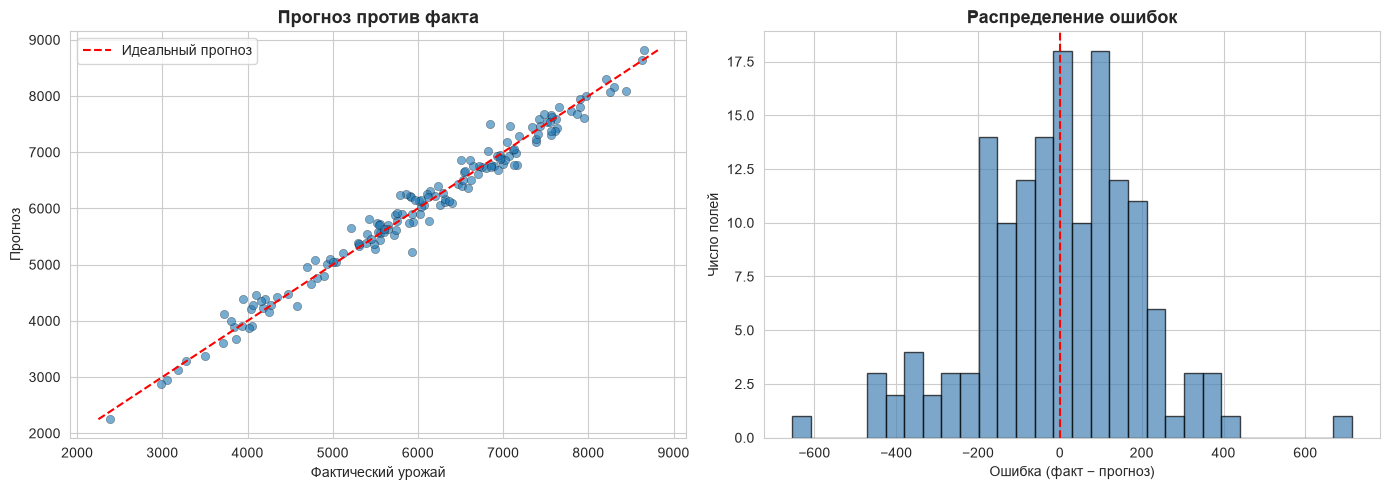

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(y_test, y_pred, alpha=0.6, edgecolor="black", linewidth=0.3)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, "r--", label="Идеальный прогноз")
ax.set_xlabel("Фактический урожай")
ax.set_ylabel("Прогноз")
ax.set_title("Прогноз против факта", fontsize=13, fontweight="bold")
ax.legend()

ax = axes[1]
residuals = y_test - y_pred
ax.hist(residuals, bins=30, color="steelblue", edgecolor="black", alpha=0.7)
ax.axvline(0, color="red", linestyle="--")
ax.set_xlabel("Ошибка (факт − прогноз)")
ax.set_ylabel("Число полей")
ax.set_title("Распределение ошибок", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

- **Слева:** чем ближе точки к красной линии, тем точнее прогноз.
- **Справа:** ошибки должны быть сосредоточены около нуля без перекоса в одну сторону — тогда модель не завышает и не занижает урожай систематически.

---
# **6. Интерпретация модели** 🔍

Для хозяйства важна не только точность, но и ответ на вопрос **«что влияет на урожай и насколько»**.

## 6.1 Важность факторов

**Permutation importance:** по очереди перемешиваем значения одного фактора в тесте и смотрим, насколько вырастет ошибка.
Чем сильнее модель «ломается» без фактора, тем он важнее.

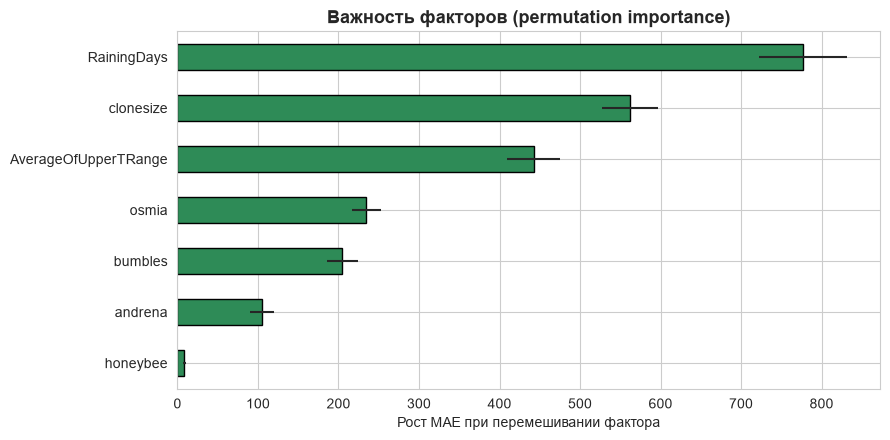

RainingDays             776.0
clonesize               562.0
AverageOfUpperTRange    442.0
osmia                   235.0
bumbles                 205.0
andrena                 105.0
honeybee                  8.0
dtype: float64

In [11]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=20,
                              scoring="neg_mean_absolute_error", random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FACTORS).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
importance.plot(kind="barh", ax=ax, color="seagreen", edgecolor="black",
                xerr=pd.Series(perm.importances_std, index=FACTORS)[importance.index])
ax.set_xlabel("Рост MAE при перемешивании фактора")
ax.set_title("Важность факторов (permutation importance)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(0)

## 6.2 Как каждый фактор влияет на урожай

**Partial dependence** показывает, как меняется прогноз урожая, если менять один фактор, а остальные оставить как в данных.
Это ответ на вопрос «что будет, если…» — но только **внутри значений, которые были в эксперименте**.

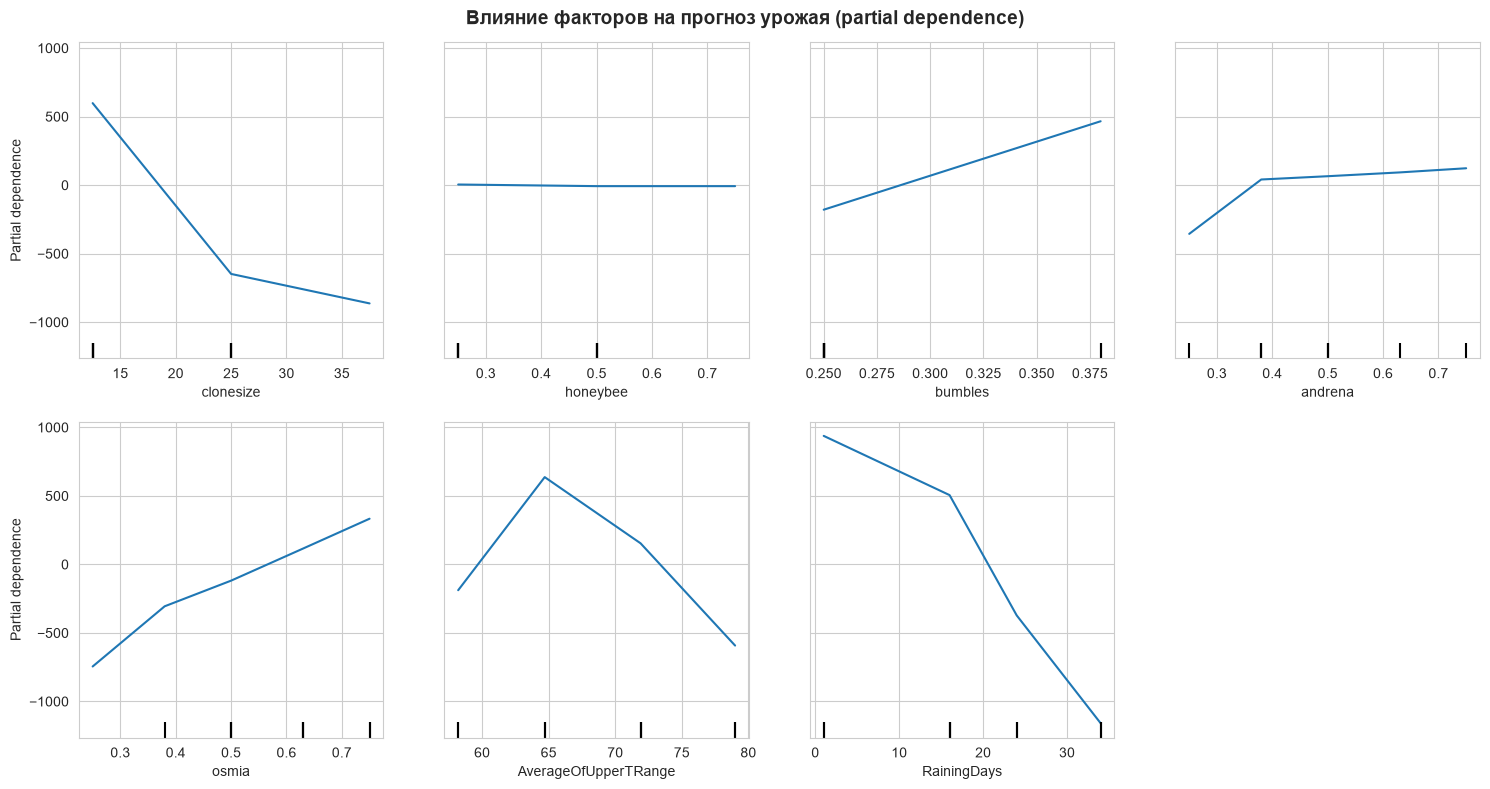

In [12]:
fig, ax = plt.subplots(figsize=(15, 8))
PartialDependenceDisplay.from_estimator(best_model, X_train, FACTORS, ax=ax,
                                        n_cols=4, grid_resolution=30)
fig.suptitle("Влияние факторов на прогноз урожая (partial dependence)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Как читать: по горизонтали — значение фактора, по вертикали — насколько прогноз урожая выше или ниже среднего (у XGBoost — сам средний прогноз). Важна форма линии.
Восходящая линия — фактор увеличивает урожай, нисходящая — уменьшает, плато — дальнейший рост фактора ничего не даёт.

## 6.3 Сценарий для хозяйства: что даст больше опылителей? 🐝

Погодой управлять нельзя, а опылителями — можно. Возьмём **типичное поле** (медианные условия) и посмотрим прогноз при разной плотности осмий и шмелей.
Берём только уровни, которые были в эксперименте, — за их пределами модель ничего не знает.

Типичное поле:


,clonesize,honeybee,bumbles,andrena,osmia,AverageOfUpperTRange,RainingDays
0,12.5,0.25,0.25,0.5,0.63,71.9,16.0


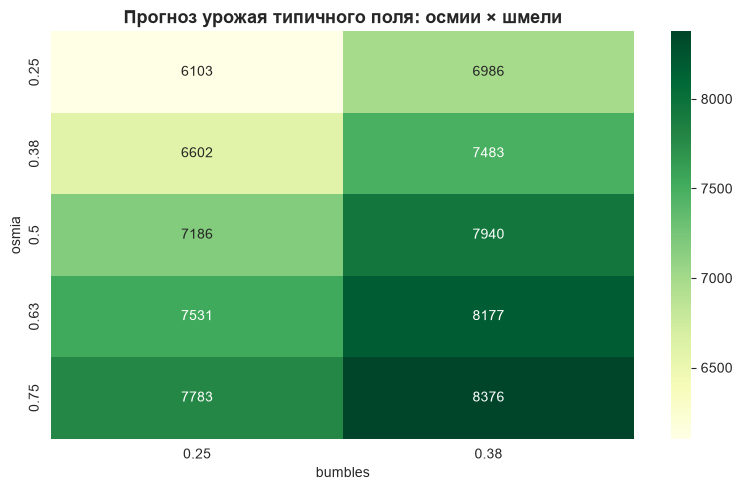

In [13]:
typical = X_train.median().to_frame().T
print("Типичное поле:")
display(typical)

osmia_levels = sorted(df_clean["osmia"].unique())
bumbles_levels = sorted(df_clean["bumbles"].unique())

grid = pd.DataFrame([{**typical.iloc[0].to_dict(), "osmia": o, "bumbles": b}
                     for o in osmia_levels for b in bumbles_levels])
grid["Прогноз урожая"] = best_model.predict(grid[FACTORS])
scenario = grid.pivot(index="osmia", columns="bumbles", values="Прогноз урожая")

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(scenario, annot=True, fmt=".0f", cmap="YlGn", ax=ax)
ax.set_title("Прогноз урожая типичного поля: осмии × шмели", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [14]:
base_pred = best_model.predict(typical[FACTORS])[0]
print(f"🫐 Прогноз для типичного поля: {base_pred:.0f}")
for col, levels in [("osmia", osmia_levels), ("bumbles", bumbles_levels)]:
    print(f"\nЕсли изменить только {col}:")
    for lvl in levels:
        row = typical.copy()
        row[col] = lvl
        p = best_model.predict(row[FACTORS])[0]
        print(f"   {col} = {lvl:<5}: {p:6.0f}  ({(p / base_pred - 1) * 100:+.1f} %)")

🫐 Прогноз для типичного поля: 7531

Если изменить только osmia:
   osmia = 0.25 :   6103  (-19.0 %)
   osmia = 0.38 :   6602  (-12.3 %)
   osmia = 0.5  :   7186  (-4.6 %)
   osmia = 0.63 :   7531  (+0.0 %)
   osmia = 0.75 :   7783  (+3.3 %)

Если изменить только bumbles:
   bumbles = 0.25 :   7531  (+0.0 %)
   bumbles = 0.38 :   8177  (+8.6 %)


⚠️ Это прогноз **модели, обученной на моделировании**, а не обещание урожая. Он показывает направление и примерный масштаб эффекта.
Перед вложениями в опылителей выводы стоит сверить с полевыми данными.

---
# **7. Сохранение модели** 💾

Сохраняем обученную модель в `models/`, чтобы её можно было загрузить без повторного обучения:
```python
import joblib
model = joblib.load("models/yield_model.joblib")
```

In [15]:
import joblib

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODELS_DIR / "yield_model.joblib"
joblib.dump({"model": best_model, "features": FACTORS, "metrics": test_metrics.to_dict()}, model_path)
print(f"✅ Модель сохранена: {model_path}")

✅ Модель сохранена: /Users/ruslan/Project-activities-case-9/models/yield_model.joblib


В Google Colab файл сохранится во временную папку сессии. Чтобы забрать его, откройте слева панель **Файлы** → папка `models` → **Скачать**.

---
# 📝 **Итоги**

Цифры ниже — с запуска на HistGradientBoosting. В Colab с XGBoost они немного отличаются, но выводы те же.

### 1. Урожай хорошо предсказывается по условиям сезона
| Модель | MAE (кросс-валидация) | R² |
|---|---|---|
| Среднее (точка отсчёта) | ≈ 1100 | 0 |
| Линейная регрессия | ≈ 510 | 0.78 |
| Random Forest | ≈ 200 | 0.96 |
| Градиентный бустинг | ≈ 165 | 0.97 |

После подбора параметров бустинг на **тесте** ошибается в среднем на **≈ 150 при среднем урожае ≈ 6000 (MAPE ≈ 2.6 %, R² ≈ 0.98)**.

### 2. Деревья лучше линейной модели
Связи нелинейные: у температуры есть оптимум (около 65 °F), у андрен прирост почти прекращается после 0.38, у осмий замедляется. Линейная регрессия этого не улавливает.

### 3. Что важнее всего для урожая
1. **Дожди** — главный фактор, больше дождей — меньше урожай.
2. **Размер клона** — крупнее клон — меньше урожай.
3. **Температура** — лучше умеренная.
4. **Осмии и шмели** — заметный плюс к урожаю.
5. Андрены — слабее; медоносные пчёлы при прочих равных почти не влияют (в эксперименте их плотность почти полностью определяется размером клона).

### 4. Что может сделать хозяйство
Для типичного поля модель прогнозирует: рост плотности **шмелей с 0.25 до 0.38 — около +9 %** урожая, **осмий с 0.63 до 0.75 — около +3 %**; при осмиях всего 0.25 урожай ниже почти на 20 %.

### 5. Ограничения
- Данные — результаты компьютерного моделирования без случайного шума, поэтому точность так высока. На реальных полях она будет ниже.
- Модель знает только уровни факторов, которые были в эксперименте. Прогнозы за их пределами ненадёжны.
- Перед реальными решениями выводы нужно сверить с полевыми данными.